CISC7204 Assignment 02 — MC63582 FAN ZIQIAN

# Practice Assignment — Part 1: Analyzing wildfire activities in Australia

## Setup

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
%matplotlib inline


## Dataset

Historical wildfires in Australia. `Year` and `Month` are taken from `Date`.

In [17]:
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv')
df['Year'] = pd.to_datetime(df['Date']).dt.year
df['Month'] = pd.to_datetime(df['Date']).dt.month
print(df.shape)
df.head()


(26406, 12)


,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced,Year,Month
0,NSW,1/4/2005,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R,2005,1
1,NSW,1/5/2005,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R,2005,1
2,NSW,1/6/2005,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R,2005,1
3,NSW,1/7/2005,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R,2005,1
4,NSW,1/8/2005,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R,2005,1


In [18]:
df.dtypes


Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
Year                                     int32
Month                                    int32
dtype: object

### TASK 1.1 Average estimated fire area over time

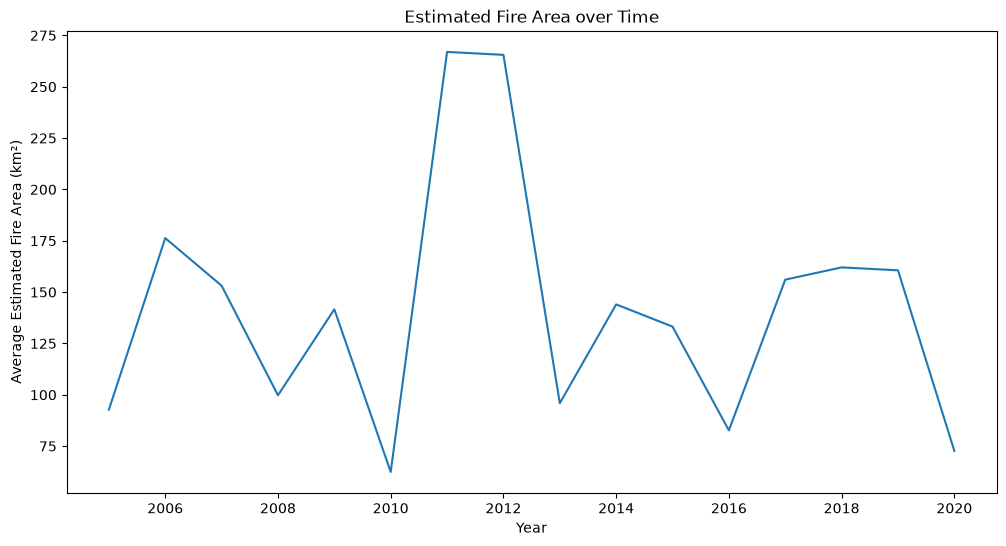

In [19]:
plt.figure(figsize=(12, 6))
df_new = df.groupby('Year')['Estimated_fire_area'].mean()
df_new.plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Average Estimated Fire Area (km²)')
plt.title('Estimated Fire Area over Time')
plt.show()


### TASK 1.2 Narrow the 2010–2013 peak: year grouped with month

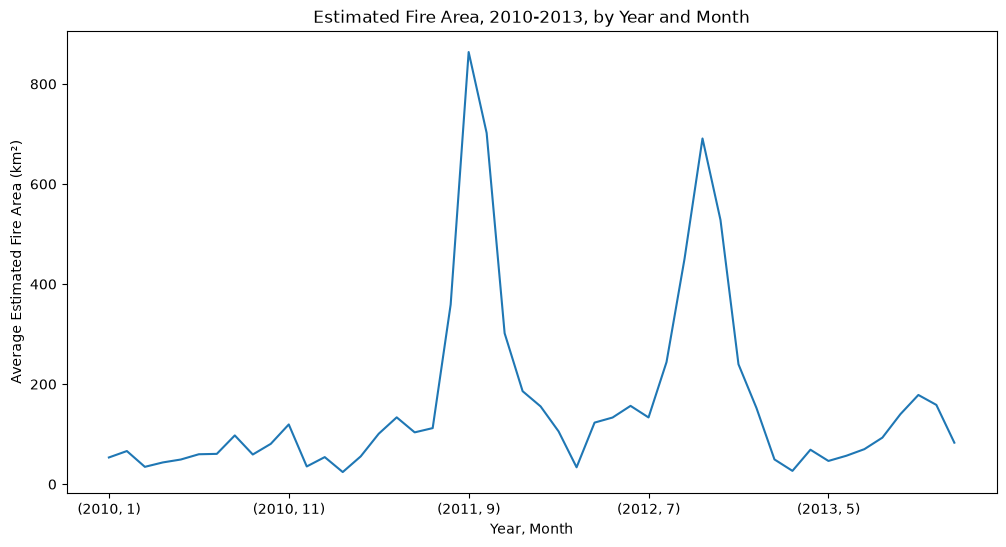

In [20]:
peak = df[(df['Year'] >= 2010) & (df['Year'] <= 2013)]
df_ym = peak.groupby(['Year', 'Month'])['Estimated_fire_area'].mean()
plt.figure(figsize=(12, 6))
df_ym.plot(kind='line')
plt.xlabel('Year, Month')
plt.ylabel('Average Estimated Fire Area (km²)')
plt.title('Estimated Fire Area, 2010-2013, by Year and Month')
plt.show()


### TASK 1.3 Mean estimated fire brightness across regions

<StringArray>
['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']
Length: 7, dtype: str


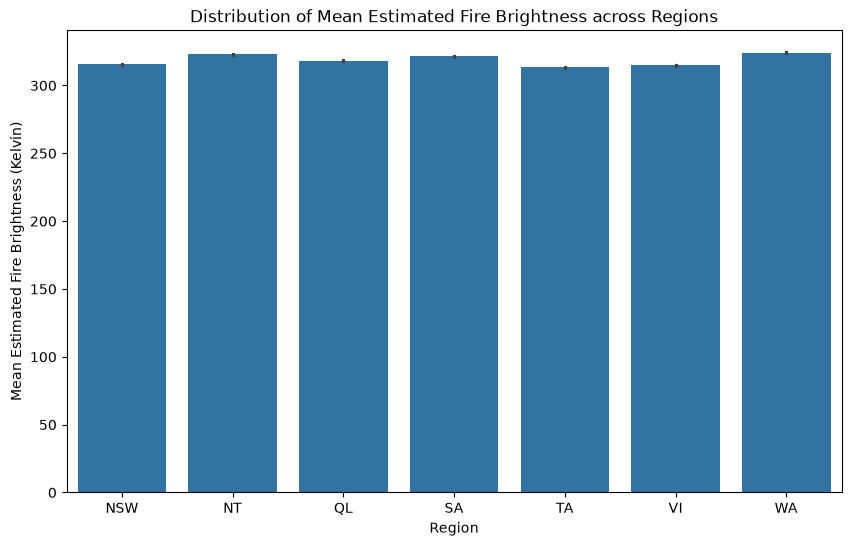

In [21]:
print(df['Region'].unique())
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Region', y='Mean_estimated_fire_brightness')
plt.xlabel('Region')
plt.ylabel('Mean Estimated Fire Brightness (Kelvin)')
plt.title('Distribution of Mean Estimated Fire Brightness across Regions')
plt.show()


### TASK 1.4 Portion of vegetation-fire pixels by region

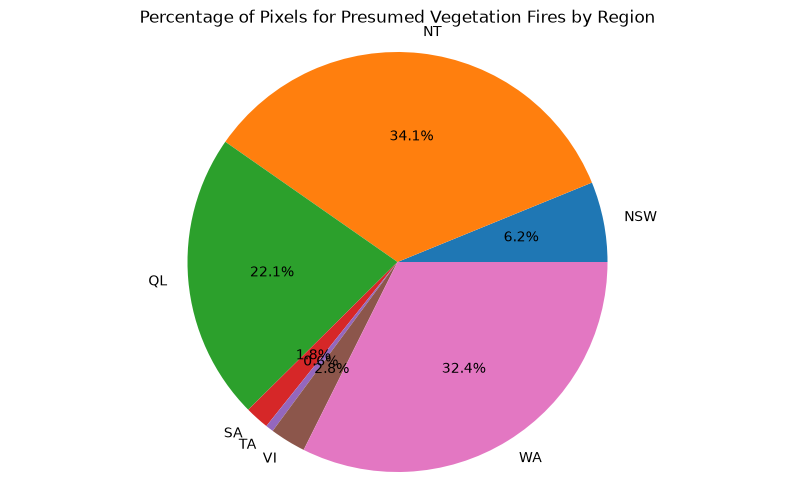

In [22]:
region_counts = df.groupby('Region')['Count'].sum()
plt.figure(figsize=(10, 6))
plt.pie(region_counts, labels=region_counts.index, autopct='%1.1f%%')
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.axis('equal')
plt.show()


### TASK 1.5 Move the overlapping percentages into the legend

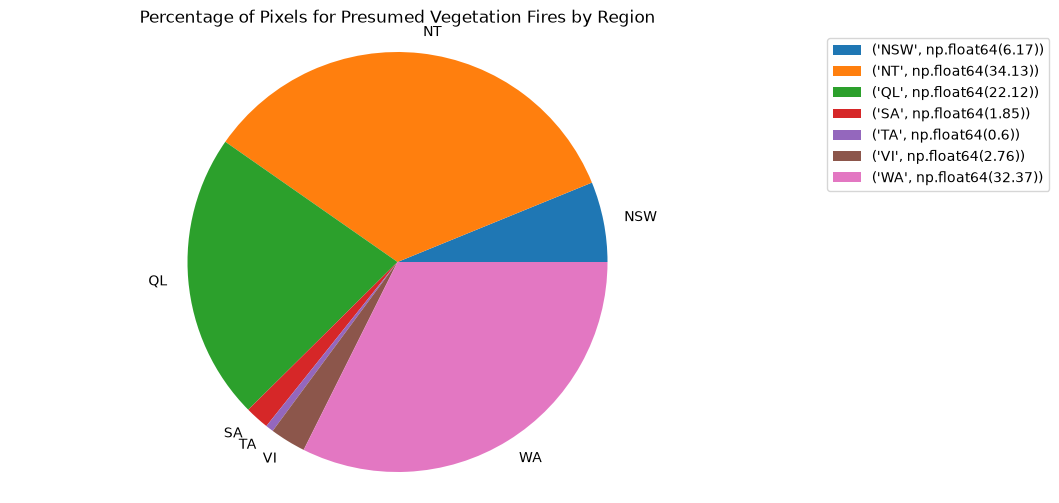

In [23]:
plt.figure(figsize=(10, 6))
plt.pie(region_counts, labels=region_counts.index)
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.legend(
    [(i, round(k / region_counts.sum() * 100, 2)) for i, k in zip(region_counts.index, region_counts)],
    loc='upper right',
    bbox_to_anchor=(1.35, 1),
)
plt.axis('equal')
plt.show()


### TASK 1.6 Histogram of mean estimated fire brightness

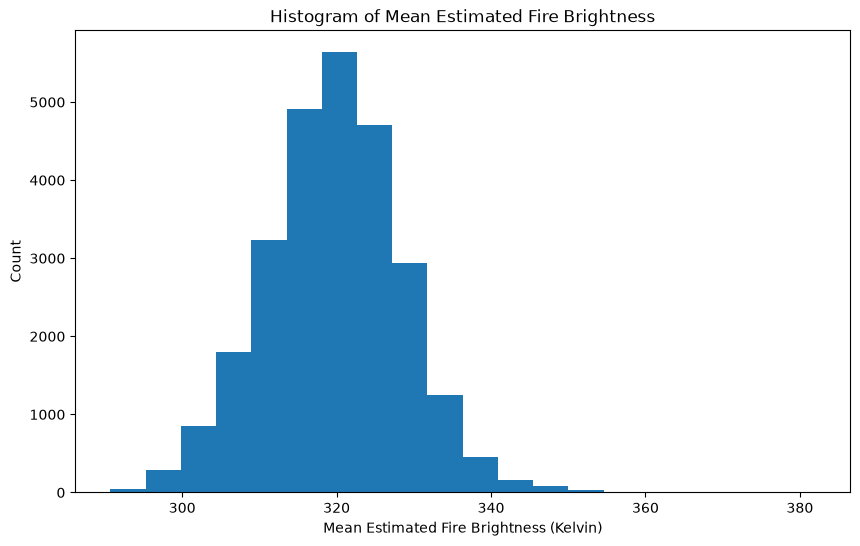

In [24]:
plt.figure(figsize=(10, 6))
plt.hist(x=df['Mean_estimated_fire_brightness'], bins=20)
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Histogram of Mean Estimated Fire Brightness')
plt.show()


### TASK 1.7 The same distribution, with region as hue, then stacked

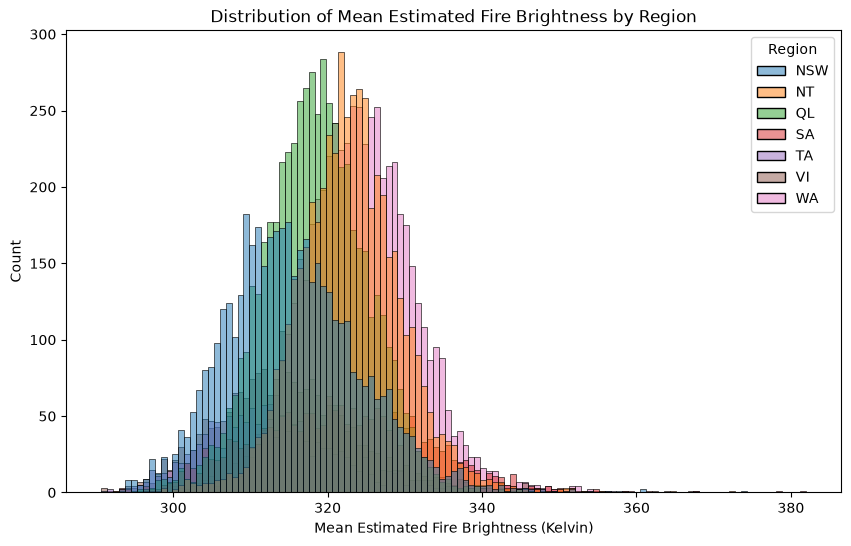

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region')
plt.title('Distribution of Mean Estimated Fire Brightness by Region')
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.show()


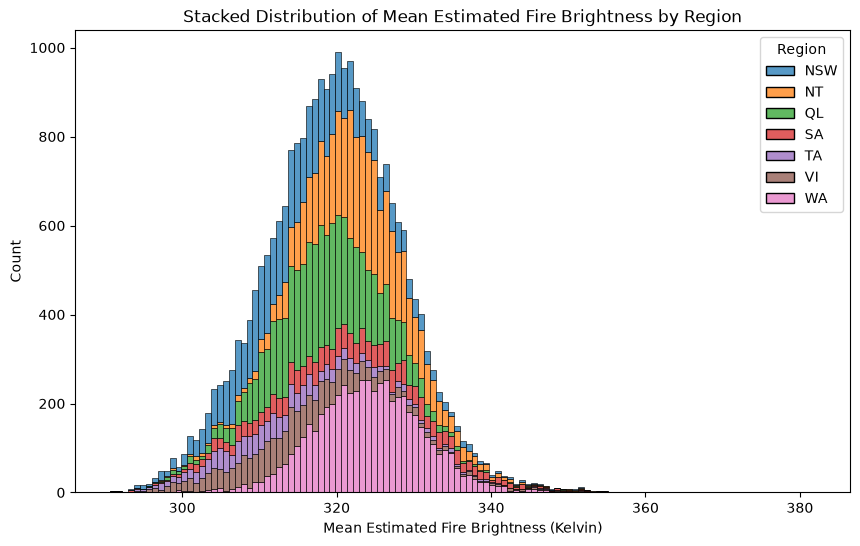

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region', multiple='stack')
plt.title('Stacked Distribution of Mean Estimated Fire Brightness by Region')
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.show()


### TASK 1.8 Mean radiative power against mean confidence

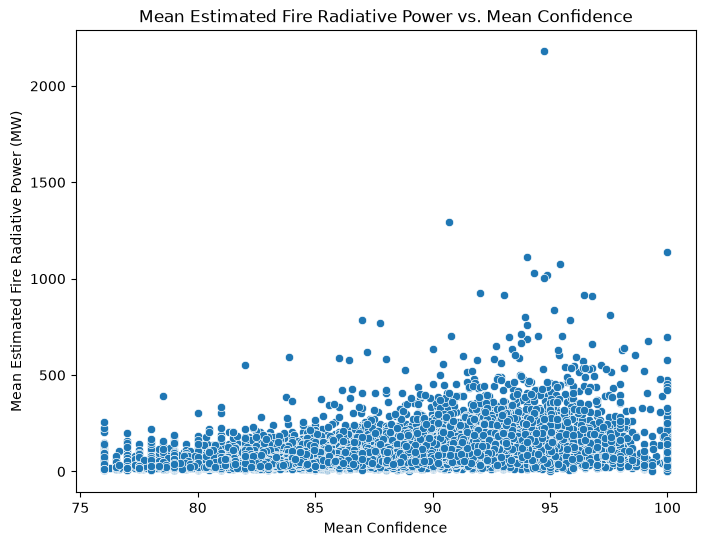

In [27]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Mean_confidence', y='Mean_estimated_fire_radiative_power')
plt.xlabel('Mean Confidence')
plt.ylabel('Mean Estimated Fire Radiative Power (MW)')
plt.title('Mean Estimated Fire Radiative Power vs. Mean Confidence')
plt.show()


### TASK 1.9 Mark the seven regions on a map of Australia

In [28]:
region_data = {
    'region': ['NSW', 'QL', 'SA', 'TA', 'VI', 'WA', 'NT'],
    'Lat': [-31.8759835, -22.1646782, -30.5343665, -42.035067, -36.5986096, -25.2303005, -19.491411],
    'Lon': [147.2869493, 144.5844903, 135.6301212, 146.6366887, 144.6780052, 121.0187246, 132.550964],
}
reg = pd.DataFrame(region_data)
aus_map = folium.Map(location=[-25, 135], zoom_start=4)
aus_reg = folium.map.FeatureGroup()
for lat, lng, lab in zip(reg.Lat, reg.Lon, reg.region):
    aus_reg.add_child(
        folium.features.CircleMarker(
            [lat, lng],
            popup=lab,
            radius=8,
            color='red',
            fill=True,
            fill_color='blue',
            fill_opacity=0.6,
        )
    )
aus_map.add_child(aus_reg)
aus_map
